In [126]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

## Importing the data

In [127]:
df = pd.read_csv("demand_forecasting.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [128]:
df.shape

(76000, 16)

In [129]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='str')

In [130]:
df.dtypes

Date                      str
Store ID                  str
Product ID                str
Category                  str
Region                    str
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Price                 float64
Discount                int64
Weather Condition         str
Promotion               int64
Competitor Pricing    float64
Seasonality               str
Epidemic                int64
Demand                  int64
dtype: object

In [131]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


## Assessing and Cleaning the Data

#### Checking for Missing Values 

In [132]:
df.isna().any()

Date                  False
Store ID              False
Product ID            False
Category              False
Region                False
Inventory Level       False
Units Sold            False
Units Ordered         False
Price                 False
Discount              False
Weather Condition     False
Promotion             False
Competitor Pricing    False
Seasonality           False
Epidemic              False
Demand                False
dtype: bool

In [133]:
df.isna().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

This dataset shows that there are no missing values in any of the columns. This means that my key variables of Inventory Level, Units Sold, Units Ordered, and Demand have data in each row. This is helpful because I will not need to evaluate whether to fill the missing values with a place holder such as NA or 0. This makes the data cleaner and prevents future inaccuracies caused by mixing data types of having incorrect 0 values impacting trends. 

#### Checking for Duplicates

In [134]:
df.duplicated(subset=None, keep='first')

0        False
1        False
2        False
3        False
4        False
         ...  
75995    False
75996    False
75997    False
75998    False
75999    False
Length: 76000, dtype: bool

In [135]:
print(df.duplicated().sum())

0


In [136]:
print(df.drop_duplicates())

             Date Store ID Product ID     Category Region  Inventory Level  \
0      2022-01-01     S001      P0001  Electronics  North              195   
1      2022-01-01     S001      P0002     Clothing  North              117   
2      2022-01-01     S001      P0003     Clothing  North              247   
3      2022-01-01     S001      P0004  Electronics  North              139   
4      2022-01-01     S001      P0005    Groceries  North              152   
...           ...      ...        ...          ...    ...              ...   
75995  2024-01-30     S005      P0016         Toys  North              233   
75996  2024-01-30     S005      P0017         Toys  North              137   
75997  2024-01-30     S005      P0018     Clothing  North              197   
75998  2024-01-30     S005      P0019    Furniture  North              125   
75999  2024-01-30     S005      P0020         Toys  North              126   

       Units Sold  Units Ordered   Price  Discount Weather Cond

There are no duplcates in my data meaning that each row is unique. This means that there are no days that were repeated for my key variables of Inventory Levels, Units Sold, Units Ordered, or Demand. It is important for these variables to not have duplicate days becuase it would cause incorrect changes to the running totals and impact the trends and eventual predictions. I would remove duplicate values to prevent these possible discrepencies in the data. 

### Checking for Outliers in Key Variables

#### Inventory Level 

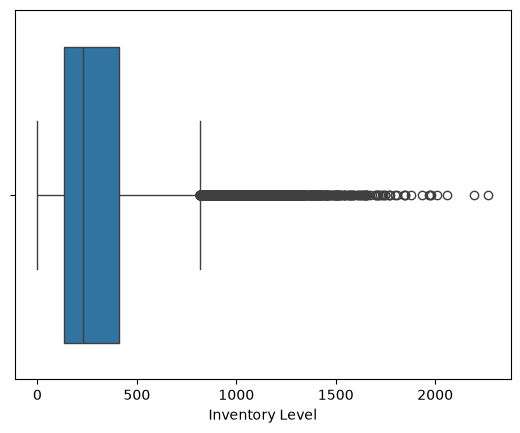

In [137]:
sns.boxplot(data=df, x="Inventory Level")
plt.show()

In [138]:
#calculating the IQR
Q1_inventory = df["Inventory Level"].quantile(0.25)
Q3_inventory = df["Inventory Level"].quantile(0.75)
IQR_inventory = Q3_inventory-Q1_inventory

In [139]:
#counting the number of outliers
inventory_outlier = df[((df["Inventory Level"]<Q1_inventory-1.5*IQR_inventory))|(df["Inventory Level"]>(Q3_inventory+1.5*IQR_inventory))]
inventory_outlier_count = inventory_outlier.count()
print(inventory_outlier_count)

Date                  2759
Store ID              2759
Product ID            2759
Category              2759
Region                2759
Inventory Level       2759
Units Sold            2759
Units Ordered         2759
Price                 2759
Discount              2759
Weather Condition     2759
Promotion             2759
Competitor Pricing    2759
Seasonality           2759
Epidemic              2759
Demand                2759
dtype: int64


#### Units Sold

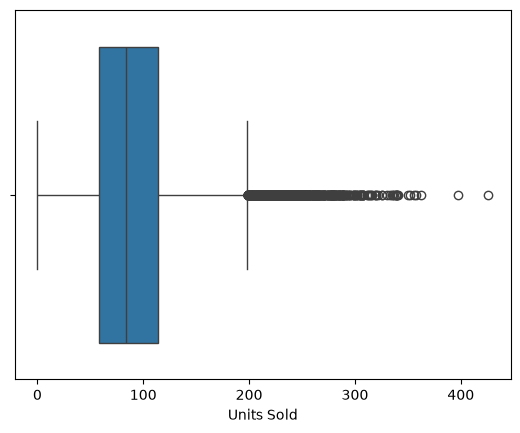

In [140]:
sns.boxplot(data=df, x="Units Sold")
plt.show()

In [141]:
#calculating the IQR
Q1_sold = df["Units Sold"].quantile(0.25)
Q3_sold = df["Units Sold"].quantile(0.75)
IQR_sold = Q3_sold-Q1_sold

In [142]:
#counting the number of outliers
sold_outlier = df[((df["Units Sold"]<Q1_sold-1.5*IQR_sold))|(df["Units Sold"]>(Q3_sold+1.5*IQR_sold))]
sold_outlier_count = sold_outlier.count()
print(sold_outlier_count)

Date                  1411
Store ID              1411
Product ID            1411
Category              1411
Region                1411
Inventory Level       1411
Units Sold            1411
Units Ordered         1411
Price                 1411
Discount              1411
Weather Condition     1411
Promotion             1411
Competitor Pricing    1411
Seasonality           1411
Epidemic              1411
Demand                1411
dtype: int64


#### Units Ordered

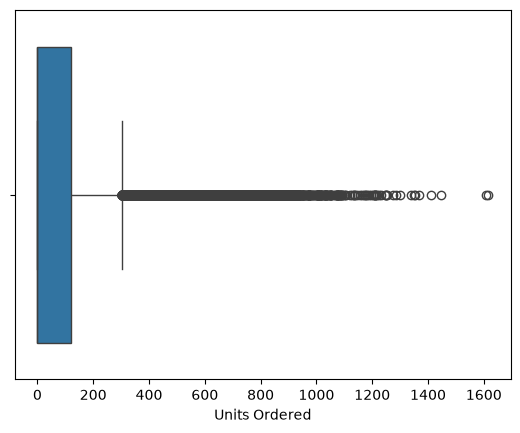

In [143]:
sns.boxplot(data=df, x="Units Ordered")
plt.show()

In [144]:
#calculating the IQR
Q1_ordered = df["Units Ordered"].quantile(0.25)
Q3_ordered = df["Units Ordered"].quantile(0.75)
IQR_ordered = Q3_ordered-Q1_ordered

In [145]:
#counting the number of outliers
ordered_outlier = df[((df["Units Ordered"]<Q1_sold-1.5*IQR_sold))|(df["Units Ordered"]>(Q3_ordered+1.5*IQR_ordered))]
ordered_outlier_count = ordered_outlier.count()
print(ordered_outlier_count)

Date                  7524
Store ID              7524
Product ID            7524
Category              7524
Region                7524
Inventory Level       7524
Units Sold            7524
Units Ordered         7524
Price                 7524
Discount              7524
Weather Condition     7524
Promotion             7524
Competitor Pricing    7524
Seasonality           7524
Epidemic              7524
Demand                7524
dtype: int64


#### Demand 

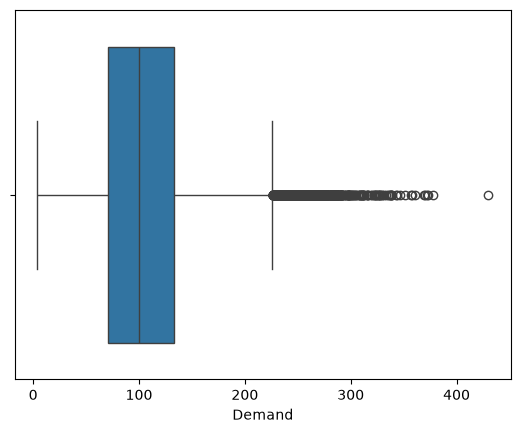

In [146]:
sns.boxplot(data=df, x="Demand")
plt.show()

In [147]:
#calculating the IQR
Q1_demand = df["Demand"].quantile(0.25)
Q3_demand = df["Demand"].quantile(0.75)
IQR_demand = Q3_demand-Q1_demand

In [148]:
#counting the number of outliers
demand_outlier = df[((df["Demand"]<Q1_demand-1.5*IQR_demand))|(df["Demand"]>(Q3_demand+1.5*IQR_demand))]
demand_outlier_count = demand_outlier.count()
print(demand_outlier_count)

Date                  986
Store ID              986
Product ID            986
Category              986
Region                986
Inventory Level       986
Units Sold            986
Units Ordered         986
Price                 986
Discount              986
Weather Condition     986
Promotion             986
Competitor Pricing    986
Seasonality           986
Epidemic              986
Demand                986
dtype: int64


The boxplots and IQR calculations reveal that there is a significant number of outliers in this dataset with there being up to 16% of the data points being outliers. Since these are key variables it is important to address these outliers to prevent them from skewing my data and predictions. There are various options such as directly removing the outliers, capping values to a specific percentile, or substituting the entries with another form of measument such as mean or median. I do not was to outrightly delete all of the values since 16% is a significant portion of my total data. For outliers in Inventory Levels and Units Ordered I will consider capping the values or using the mean since these variables are comprised of more than 2-3% outliers. However, this risks a loss in data variablity and may create a blind spot for my predictive models later on. For the other key variables of Units Sold and Demand I will consider removing these outliers since they make up less than 3% of the data points. However, this creates the risk of generating bias in my model and so I will continue to consider other options. 

#### Handling Outliers 

#### Inventory 

In [149]:
# Setting the lower and upper limit 
lower_inventory = df["Inventory Level"].quantile(0.05)
upper_inventory = df["Inventory Level"].quantile(0.95) 

In [150]:
# Capping Inventory Level within the set range
df["Inventory Level"] = df["Inventory Level"].clip(lower=lower_inventory)
df["Inventory Level"] = df["Inventory Level"].clip(upper=upper_inventory)

#### Units Sold

In [151]:
# Setting the lower and upper limit 
lower_sold = df["Units Sold"].quantile(0.05)
upper_sold = df["Units Sold"].quantile(0.95) 

In [152]:
# Capping Unit Sold within the set range
df["Units Sold"] = df["Units Sold"].clip(lower=lower_sold)
df["Units Sold"] = df["Units Sold"].clip(upper=upper_sold)

#### Units Ordered

In [153]:
# Setting the lower and upper limit 
lower_ordered = df["Units Ordered"].quantile(0.05)
upper_ordered = df["Units Ordered"].quantile(0.95) 

In [154]:
# Capping Unit Ordered within the set range
df["Units Ordered"] = df["Units Ordered"].clip(lower=lower_ordered)
df["Units Ordered"] = df["Units Ordered"].clip(upper=upper_ordered)

#### Demand 

In [155]:
# Setting the lower and upper limit 
lower_demand = df["Demand"].quantile(0.05)
upper_demand = df["Demand"].quantile(0.95) 

In [156]:
# Capping Demand within the set range
df["Demand"] = df["Demand"].clip(lower=lower_demand)
df["Demand"] = df["Demand"].clip(upper=upper_demand)

#### Justification
I decided to cap each of the key variables at thier 5th and 95th percentiles as a way to address outliers. I did this becuase there was a significant amount of outliers in my data, up to 16% of all rows. I did not want to delete that amount of valuable data without knowing if it was done in error or if it were actually extreme values. Additionally, I did not want to substitute each of the outlier variables with central tendency measurments becuase I still wanted data points that would reflect the significant increase or decrease in the value. These key variable were already skewed and so I thought capping the outliers at the 5th and 95th percentiles was in the best interest for a semblance of accuracy in visualizations, analysis, and future predictions. 

### Checking for Inconsistencies in Categorical Variables

In [157]:
df["Category"].value_counts()

Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

In [158]:
df["Region"].value_counts()

Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

In [159]:
df["Weather Condition"].value_counts()

Weather Condition
Cloudy    24360
Sunny     22980
Rainy     17500
Snowy     11160
Name: count, dtype: int64

In [160]:
df["Seasonality"].value_counts()

Seasonality
Winter    21000
Spring    18400
Summer    18400
Autumn    18200
Name: count, dtype: int64

These lists of the different values under each cateorical column shows how there are no inconsistencies in the data. None of the columns show any unknown or inconsistant spelling of the variable options. While these are not part of my key variables, it is still important to have these categorical variables cleaned to avoid running into future issues. For example, it is important to have these variables cleaned in case future analysis ties in any of these categories. 

### Exploratory Analysis 

#### Distribution 

<Axes: >

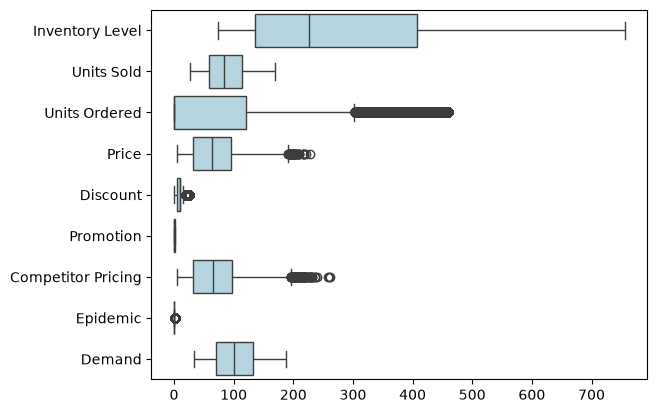

In [173]:
#show distribution of all numerical variables 
sns.boxplot(data=df, color="lightblue", orient="h")

<Axes: >

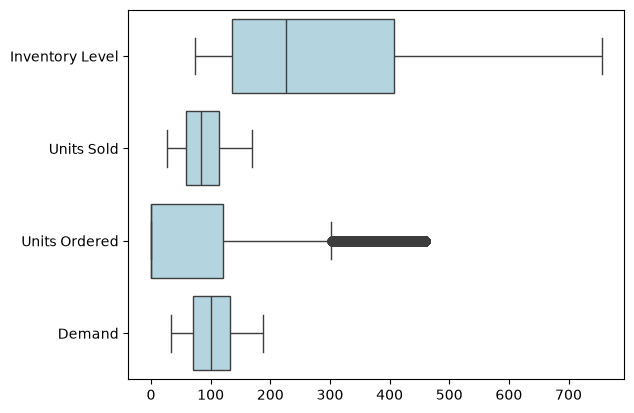

In [177]:
#show distribution of key variables including my target variable of "Inventory Level"
sns.boxplot(data=df[["Inventory Level", "Units Sold", "Units Ordered", "Demand"]], color='lightblue', orient='h')

#### Possible Relationships 

<Axes: xlabel='Date', ylabel='Inventory Level'>

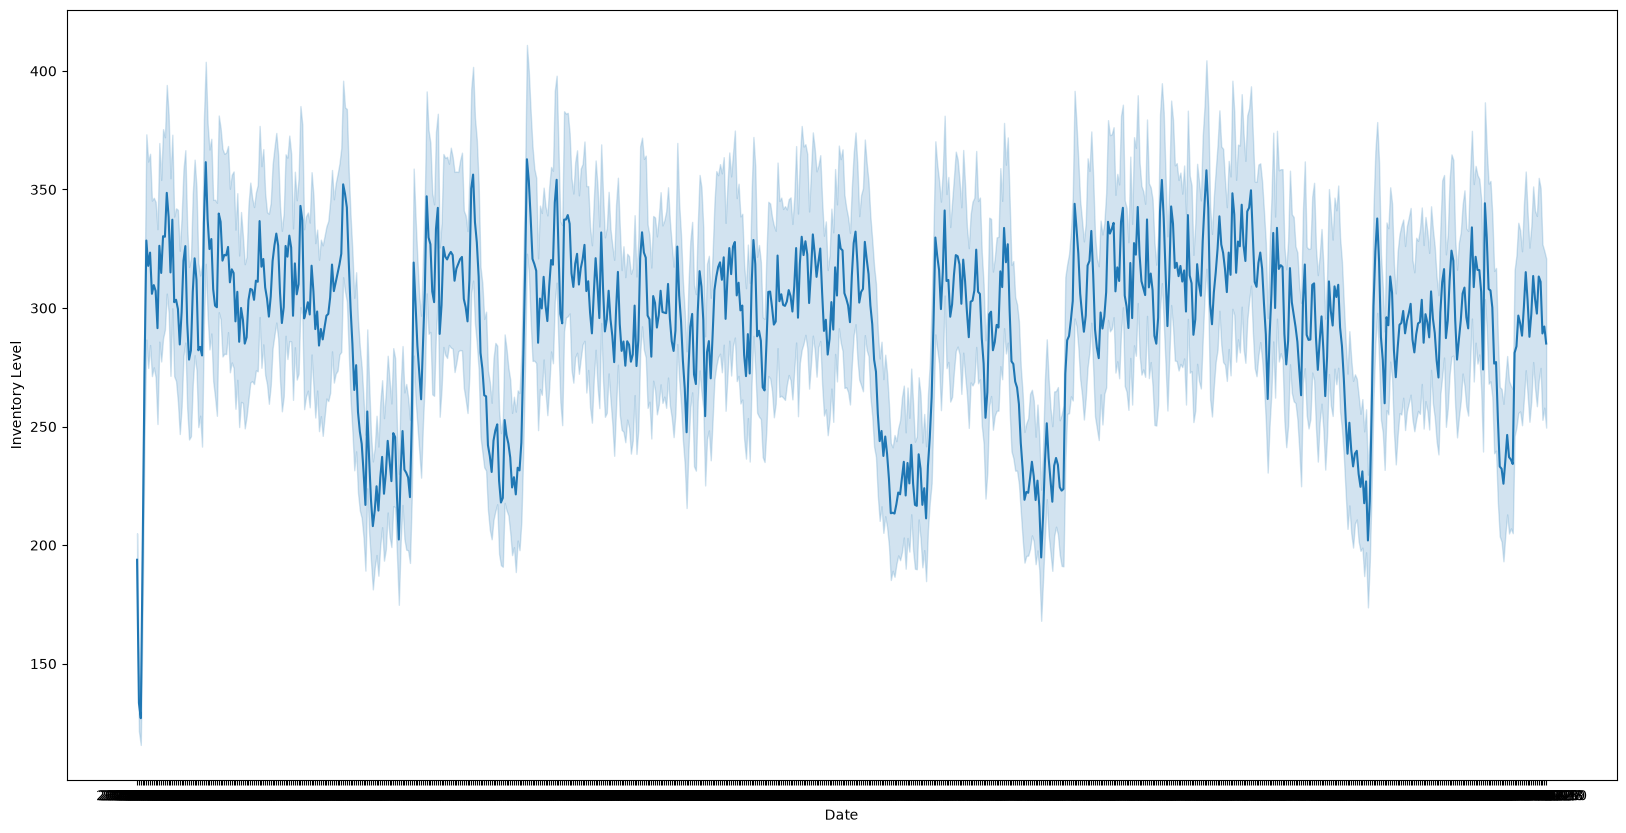

In [239]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Date', y='Inventory Level')

This line chart show how the Inventory Level changes overtime. The large dips at somewhat regular intervals leads me to wonder if seasonality is involved. 

<Axes: xlabel='Date', ylabel='Demand'>

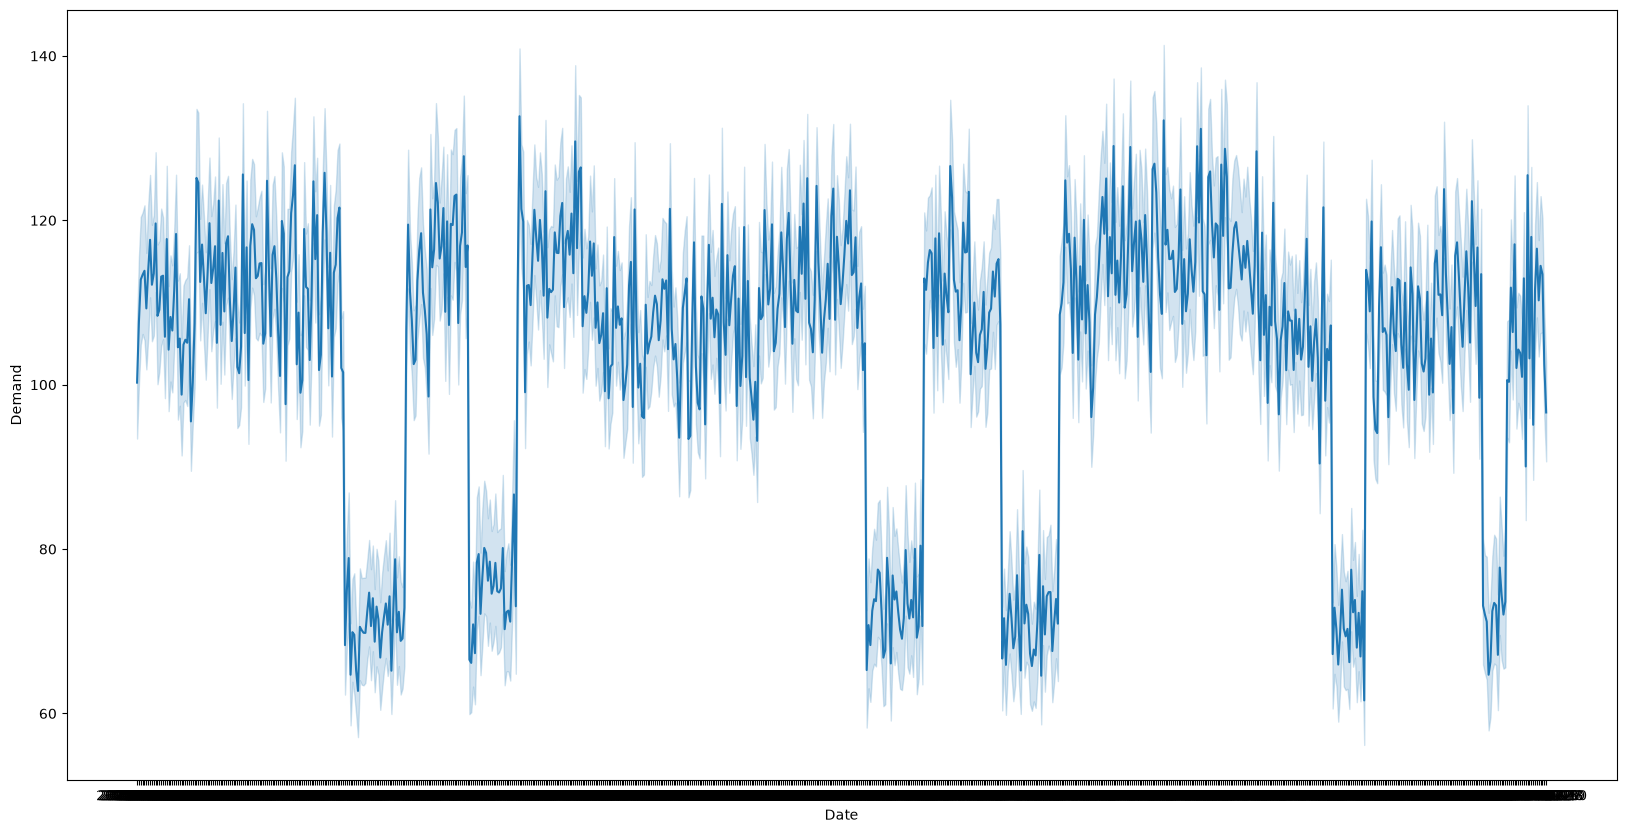

In [242]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Date', y='Demand')

This line chart has a similar shape to the Inventory Level chart. This leads me to believe there is a possible underlying relationship. Additionally, this reinforces my possible ideas regarding seasonality. 

<Axes: xlabel='Demand', ylabel='Inventory Level'>

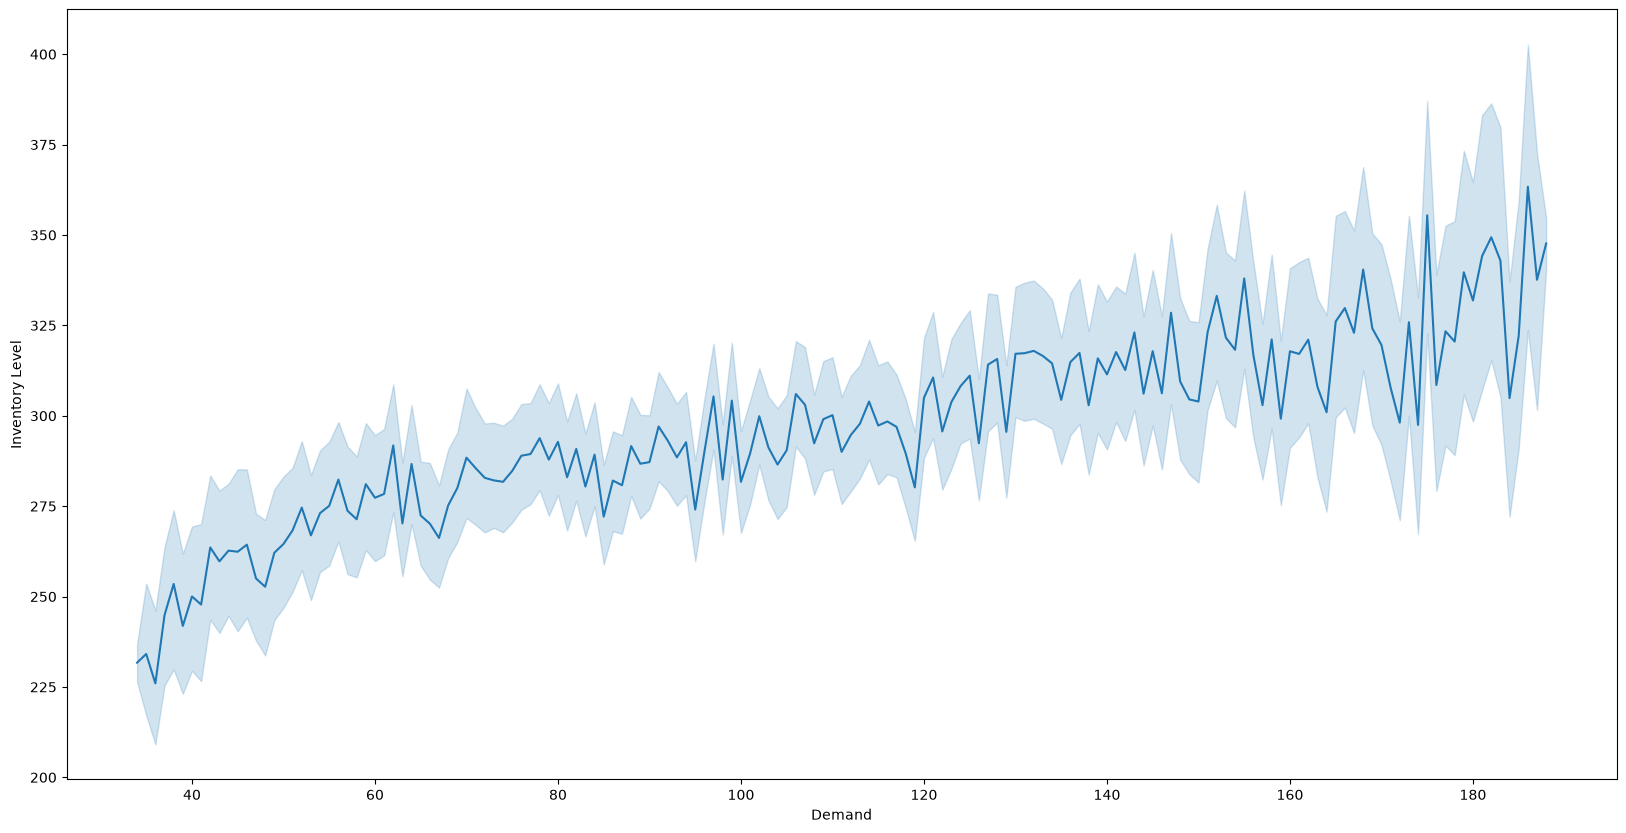

In [241]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Demand', y='Inventory Level')

While not perfectly smooth this chart is showing a roughly positive relationship between Demand and the target variable of Inventory Level. This will be helpful when considering predictions. 

#### Correlation

<Axes: >

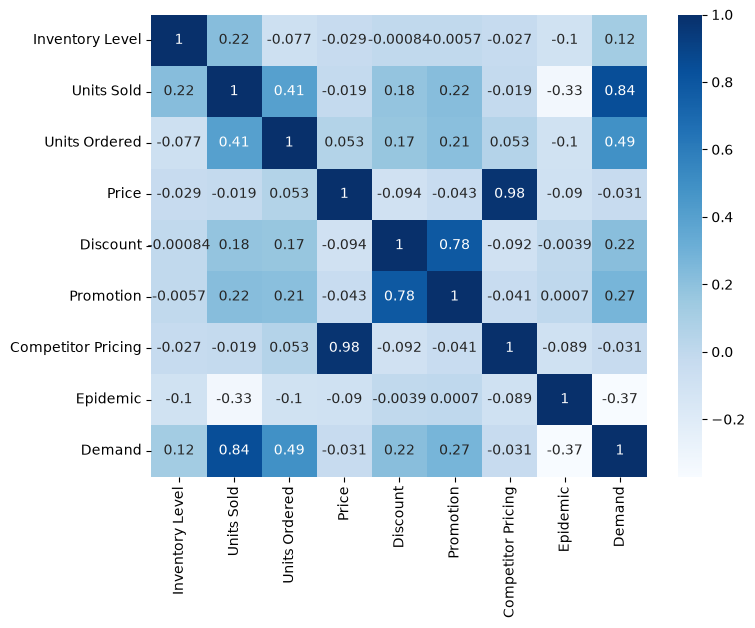

In [238]:
plt.figure(figsize=(8,6))
correlation_matrix = df.corr(numeric_only=True) 
sns.heatmap(correlation_matrix, annot=True, cmap='Blues')

My main concern or surprise comes from this heatmap where I can see that my target variable of Invenroy Level does not have as of high of a correlation with the other variables as I had originally assumed. This is causing me to question if I will need to pivot my project or consider other variables more highly. 